In [25]:
pip install wget

In [26]:
from pathlib import Path
import os
os.environ["KERAS_HOME"] = str(Path.cwd() / ".tools" / "keras")
import zipfile
import wget
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

tf.keras.utils.set_random_seed(42)
gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

print("TensorFlow :", tf.__version__)
print("GPU :", gpus if gpus else "Tidak terdeteksi ; pelatihan menggunakan CPU.")
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
EPOCHS = 10

TensorFlow : 2.21.0
GPU : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [27]:
url = "https://mymldatasets.s3.eu-de.cloud-object-storage.appdomain.cloud/UCMerced_LandUse.zip"
data_dir = Path("data")
data_dir.mkdir(exist_ok=True)
zip_path = data_dir / "UCMerced_LandUse.zip"

if not zip_path.exists():
    wget.download(url, out=str(zip_path))

with zipfile.ZipFile(zip_path) as arsip:
    for nama in arsip.namelist():
        tujuan = (data_dir / nama).resolve()
        if not tujuan.is_relative_to(data_dir.resolve()):
            raise ValueError("Lokasi file ZIP tidak valid")
    arsip.extractall(data_dir)

image_dir = data_dir / "dataset" / "Images"
print("Folder gambar :", image_dir)

Folder gambar : data/dataset/Images


In [28]:
url = "https://mymldatasets.s3.eu-de.cloud-object-storage.appdomain.cloud/UCMerced_LandUse.zip"
data_dir = Path("data")
data_dir.mkdir(exist_ok=True)
zip_path = data_dir / "UCMerced_LandUse.zip"

if not zip_path.exists():
    wget.download(url, out=str(zip_path))

with zipfile.ZipFile(zip_path) as arsip:
    for nama in arsip.namelist():
        tujuan = (data_dir / nama).resolve()
        if not tujuan.is_relative_to(data_dir.resolve()):
            raise ValueError("Lokasi file ZIP tidak valid")
    arsip.extractall(data_dir)

image_dir = data_dir / "dataset" / "Images"
print("Folder gambar :", image_dir)

# Memuat data gambar untuk mendefinisikan nama_kelas, X, dan y
nama_kelas = sorted([d.name for d in image_dir.iterdir() if d.is_dir()])
X = []
y = []

for label_idx, kelas in enumerate(nama_kelas):
    kelas_dir = image_dir / kelas
    for img_path in kelas_dir.glob("*.tif"):
        img = Image.open(img_path).resize(IMG_SIZE)
        X.append(np.array(img))
        y.append(label_idx)

X = np.array(X)
y = np.array(y)

# Memastikan kelengkapan dataset sesuai dengan assert
assert len(nama_kelas) == 21 and len(X) == 2100, \
" Periksa kelengkapan dataset "
assert np.all(np.bincount(y) == 100), \
" Setiap kelas seharusnya memiliki 100 gambar "
print(" Bentuk data :", X.shape)
print(" Kelas :", nama_kelas)

Folder gambar : data/dataset/Images
 Bentuk data : (2100, 224, 224, 3)
 Kelas : ['agricultural', 'airplane', 'baseballdiamond', 'beach', 'buildings', 'chaparral', 'denseresidential', 'forest', 'freeway', 'golfcourse', 'harbor', 'intersection', 'mediumresidential', 'mobilehomepark', 'overpass', 'parkinglot', 'river', 'runway', 'sparseresidential', 'storagetanks', 'tenniscourt']


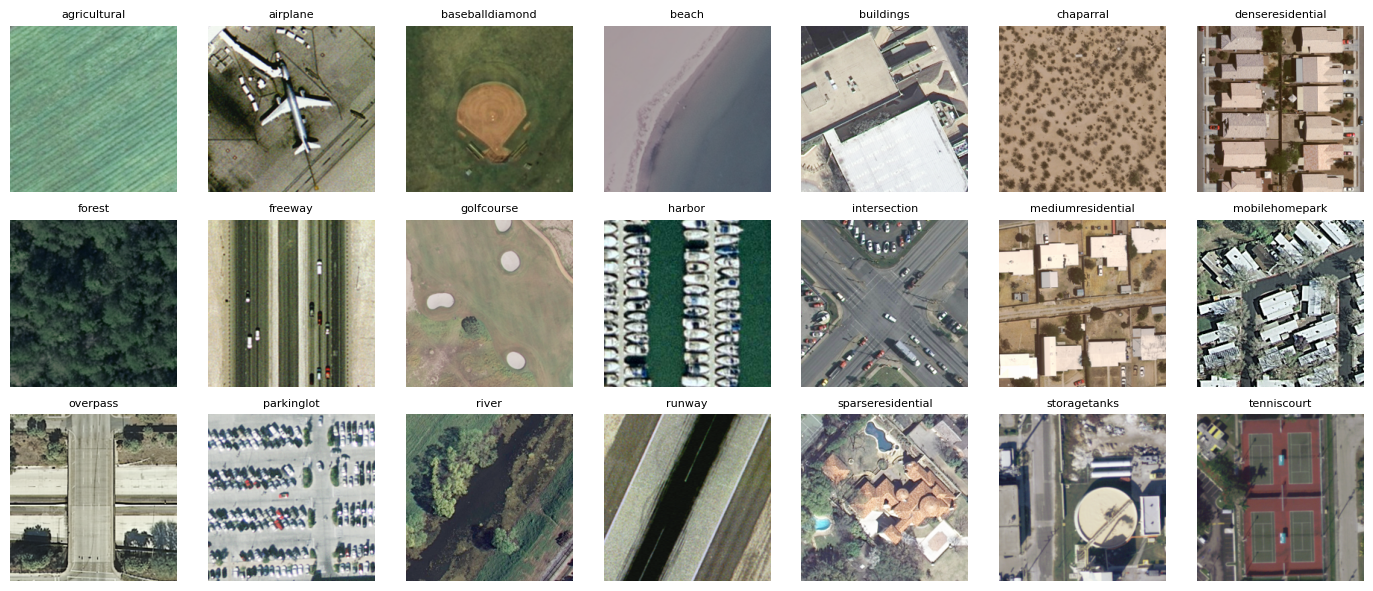

In [29]:
fig, axes = plt.subplots(3, 7, figsize=(14, 6))
for kelas, ax in enumerate(axes.flat):
    idx = np.flatnonzero(y == kelas)[0]
    ax.imshow(X[idx])
    ax.set_title(nama_kelas[kelas], fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [30]:
x_train , x_sisa , y_train , y_sisa = train_test_split (
X ,
y ,
test_size =0.30 ,
stratify =y ,
random_state =42
)
x_val , x_test , y_val , y_test = train_test_split (
x_sisa ,
y_sisa ,
test_size =0.50 ,
stratify = y_sisa ,
random_state =42
)
print (
" Train :",
len ( y_train ) ,
" Validation :",
len ( y_val ) ,
" Test :",
len ( y_test )
)

 Train : 1470  Validation : 315  Test : 315


1. Gunakan arsitektur VGG untuk melatih data nya.

In [31]:
base_model = tf.keras.applications.VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(*IMG_SIZE, 3)
)
base_model.trainable = False

inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))
x = tf.keras.applications.vgg16.preprocess_input(inputs)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(
    len(nama_kelas),
    activation="softmax"
)(x)

model = tf.keras.Model(
    inputs,
    outputs,
    name="vgg16_ucmerced"
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()
print("Backbone dibekukan :", not base_model.trainable)

Model: "vgg16_ucmerced"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_3          │ (None, 224, 224)  │          0 │ input_layer_5[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_4          │ (None, 224, 224)  │          0 │ input_layer_5[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_5          │ (None, 224, 224)  │          0 │ input_layer_5[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack_1 (Stack)     │ (None, 224, 224,  │          0 │ get_item_3[0][0], │
│                     │ 3)                │            │ get_item_4[0][0], │
│                     │                   │            │ get_item_5[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 224, 224,  │          0 │ stack_1[0][0]     │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg16 (Functional)  │ (None, 7, 7, 512) │ 14,714,688 │ add_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 512)       │          0 │ vgg16[0][0]       │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 512)       │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 21)        │     10,773 │ dropout_2[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 14,725,461 (56.17 MB)

 Trainable params: 10,773 (42.08 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

Backbone dibekukan : True


In [32]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop],
    verbose=2
)

print("Epoch dijalankan :", len(history.history["loss"]))

Epoch 1/10
92/92 - 13s - 141ms/step - accuracy: 0.2238 - loss: 5.4435 - val_accuracy: 0.5460 - val_loss: 1.8078
Epoch 2/10
92/92 - 8s - 85ms/step - accuracy: 0.5878 - loss: 1.9041 - val_accuracy: 0.7429 - val_loss: 0.9437
Epoch 3/10
92/92 - 8s - 83ms/step - accuracy: 0.7170 - loss: 1.1558 - val_accuracy: 0.7937 - val_loss: 0.6932
Epoch 4/10
92/92 - 7s - 81ms/step - accuracy: 0.8163 - loss: 0.7313 - val_accuracy: 0.8349 - val_loss: 0.5536
Epoch 5/10
92/92 - 7s - 80ms/step - accuracy: 0.8299 - loss: 0.5768 - val_accuracy: 0.8349 - val_loss: 0.4824
Epoch 6/10
92/92 - 7s - 79ms/step - accuracy: 0.8660 - loss: 0.4164 - val_accuracy: 0.8730 - val_loss: 0.3975
Epoch 7/10
92/92 - 7s - 78ms/step - accuracy: 0.8952 - loss: 0.3449 - val_accuracy: 0.8730 - val_loss: 0.3602
Epoch 8/10
92/92 - 7s - 79ms/step - accuracy: 0.9082 - loss: 0.3070 - val_accuracy: 0.8952 - val_loss: 0.2932
Epoch 9/10
92/92 - 7s - 79ms/step - accuracy: 0.9204 - loss: 0.2622 - val_accuracy: 0.8921 - val_loss: 0.2899
Epoch 10

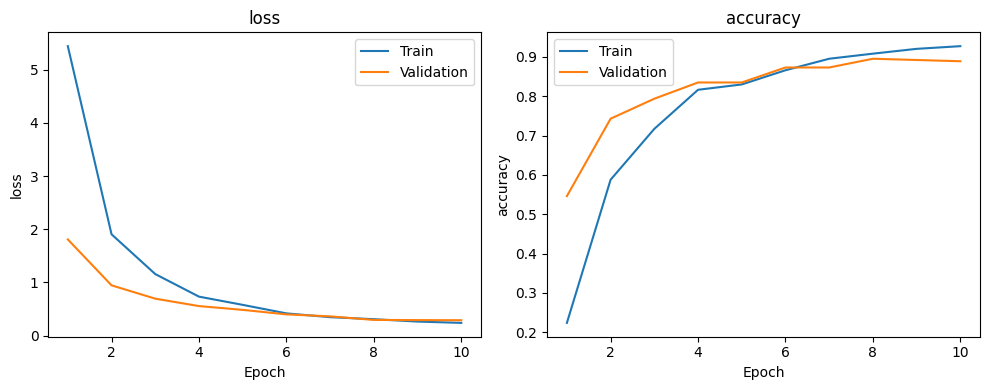

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
epochs = range(1, len(history.history["loss"]) + 1)

for ax, metric in zip(axes, ["loss", "accuracy"]):
    ax.plot(
        epochs,
        history.history[metric],
        label="Train"
    )
    ax.plot(
        epochs,
        history.history["val_" + metric],
        label="Validation"
    )
    ax.set(
        xlabel="Epoch",
        ylabel=metric,
        title=metric
    )
    ax.legend()

plt.tight_layout()
plt.show()

Test loss : 0.2598 | Test accuracy : 92.70%
                   precision    recall  f1-score   support

     agricultural       1.00      1.00      1.00        15
         airplane       1.00      1.00      1.00        15
  baseballdiamond       1.00      0.93      0.97        15
            beach       1.00      1.00      1.00        15
        buildings       0.88      0.47      0.61        15
        chaparral       1.00      1.00      1.00        15
 denseresidential       0.74      0.93      0.82        15
           forest       0.88      0.93      0.90        15
          freeway       1.00      1.00      1.00        15
       golfcourse       0.93      0.93      0.93        15
           harbor       1.00      1.00      1.00        15
     intersection       0.87      0.87      0.87        15
mediumresidential       0.94      1.00      0.97        15
   mobilehomepark       1.00      0.93      0.97        15
         overpass       1.00      0.87      0.93        15
       park

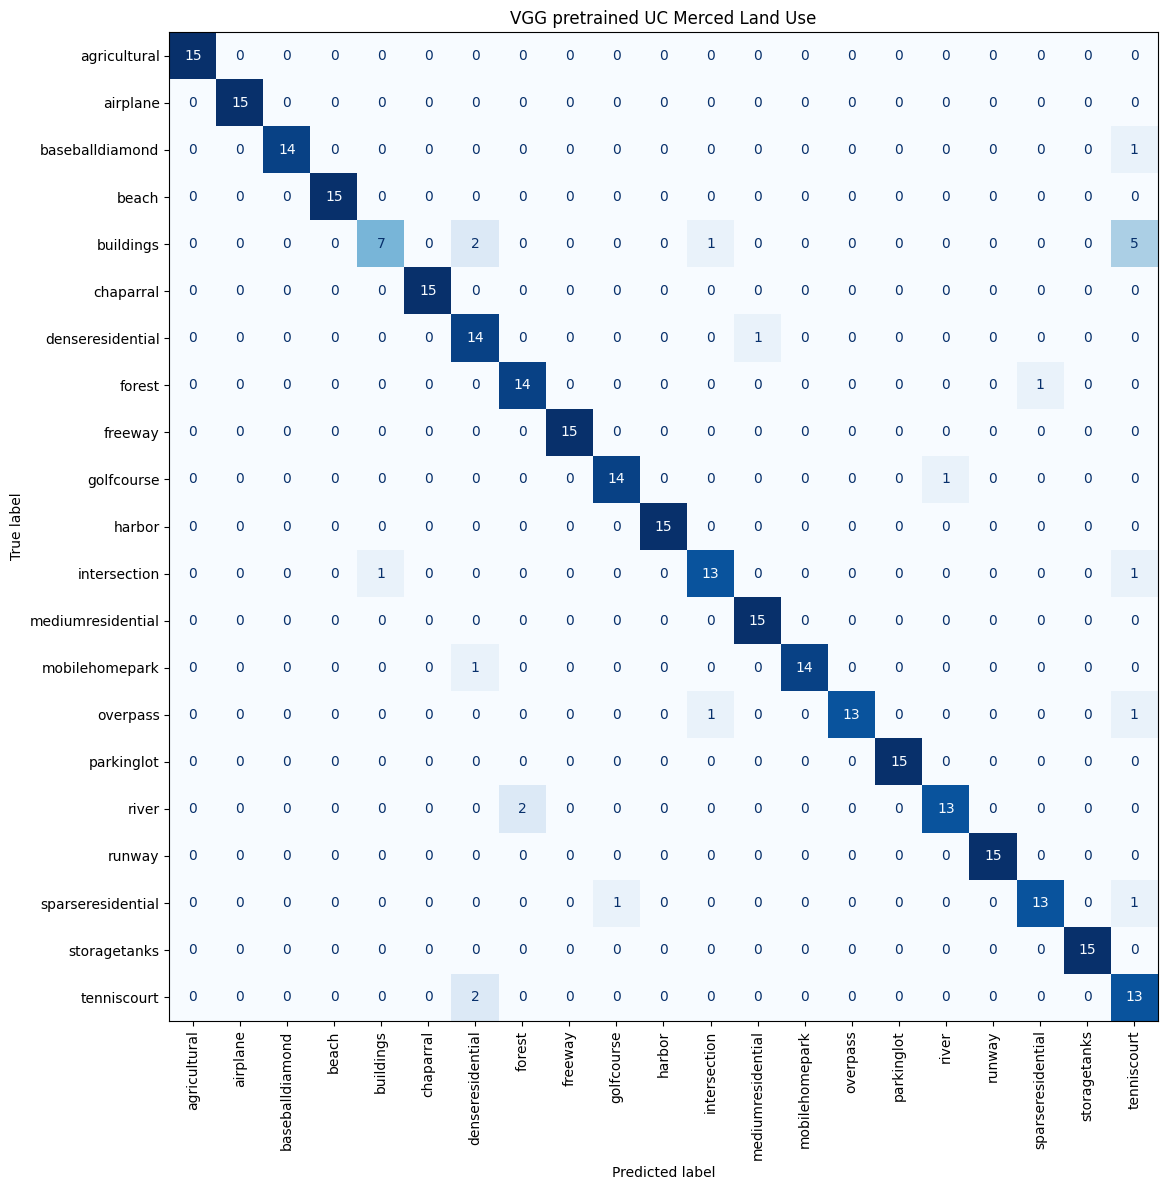

In [34]:
test_loss, test_acc = model.evaluate(
    x_test,
    y_test,
    verbose=0
)

probabilitas = model.predict(
    x_test, batch_size=BATCH_SIZE,
    verbose=0
)

y_pred = probabilitas.argmax(axis=1)

print(
    f"Test loss : {test_loss:.4f} | "
    f"Test accuracy : {test_acc:.2%}"
)

assert np.isclose(
    test_acc,
    np.mean(y_pred == y_test),
    atol=1e-6
)

print(
    classification_report(
        y_test,
        y_pred,
        target_names=nama_kelas,
        zero_division=0
    )
)

fig, ax = plt.subplots(figsize=(14, 12))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=nama_kelas,
    cmap="Blues",
    xticks_rotation=90,
    colorbar=False,
    ax=ax
)

ax.set_title("VGG pretrained UC Merced Land Use")
plt.tight_layout()
plt.show()

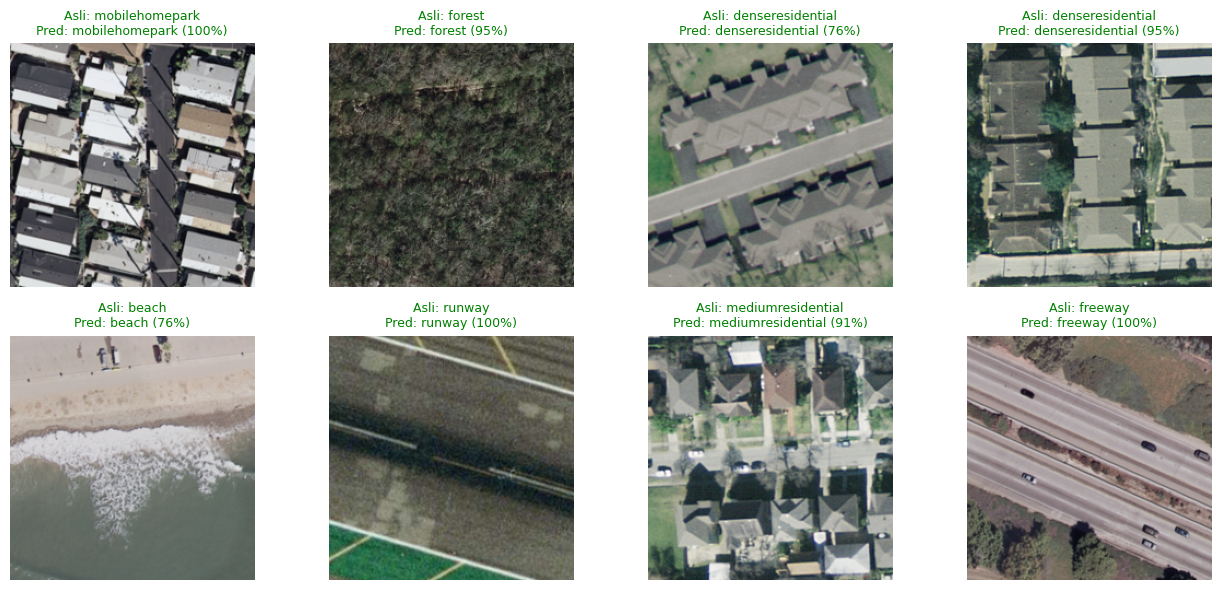

In [35]:
fig, axes = plt.subplots(2, 4, figsize=(13, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_test[i])
    ax.set_title(
        f"Asli: {nama_kelas[y_test[i]]}\n"
        f"Pred: {nama_kelas[y_pred[i]]} "
        f"({probabilitas[i].max():.0%})",
        fontsize=9,
        color="green" if y_test[i] == y_pred[i] else "red"
    )
    ax.axis("off")
plt.tight_layout()
plt.show()

2. Gunakan arsitektur lain (AlexNet, MobileNet, dsb) untuk melatih data nya.


a. mobilenet

In [36]:
base_model = tf.keras.applications.MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(*IMG_SIZE, 3)
)
base_model.trainable = False

inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))
x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)

outputs = tf.keras.layers.Dense(
    len(nama_kelas),
    activation="softmax"
)(x)

model = tf.keras.Model(
    inputs,
    outputs,
    name="mobilenetv2_ucmerced"
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()
print("Backbone dibekukan :", not base_model.trainable)

Model: "mobilenetv2_ucmerced"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_1 (Subtract)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 21)             │        26,901 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,284,885 (8.72 MB)

 Trainable params: 26,901 (105.08 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Backbone dibekukan : True


In [37]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop],
    verbose=2
)

print("Epoch dijalankan :", len(history.history["loss"]))

Epoch 1/10
92/92 - 17s - 189ms/step - accuracy: 0.5633 - loss: 1.5456 - val_accuracy: 0.8635 - val_loss: 0.5191
Epoch 2/10
92/92 - 2s - 20ms/step - accuracy: 0.8973 - loss: 0.3707 - val_accuracy: 0.9238 - val_loss: 0.3157
Epoch 3/10
92/92 - 2s - 19ms/step - accuracy: 0.9544 - loss: 0.2121 - val_accuracy: 0.9270 - val_loss: 0.2553
Epoch 4/10
92/92 - 2s - 19ms/step - accuracy: 0.9721 - loss: 0.1359 - val_accuracy: 0.9365 - val_loss: 0.2247
Epoch 5/10
92/92 - 2s - 19ms/step - accuracy: 0.9810 - loss: 0.0998 - val_accuracy: 0.9333 - val_loss: 0.2125
Epoch 6/10
92/92 - 2s - 19ms/step - accuracy: 0.9871 - loss: 0.0751 - val_accuracy: 0.9397 - val_loss: 0.1923
Epoch 7/10
92/92 - 2s - 19ms/step - accuracy: 0.9939 - loss: 0.0613 - val_accuracy: 0.9397 - val_loss: 0.1906
Epoch 8/10
92/92 - 2s - 19ms/step - accuracy: 0.9946 - loss: 0.0491 - val_accuracy: 0.9333 - val_loss: 0.1811
Epoch 9/10
92/92 - 2s - 18ms/step - accuracy: 0.9952 - loss: 0.0438 - val_accuracy: 0.9397 - val_loss: 0.1833
Epoch 10

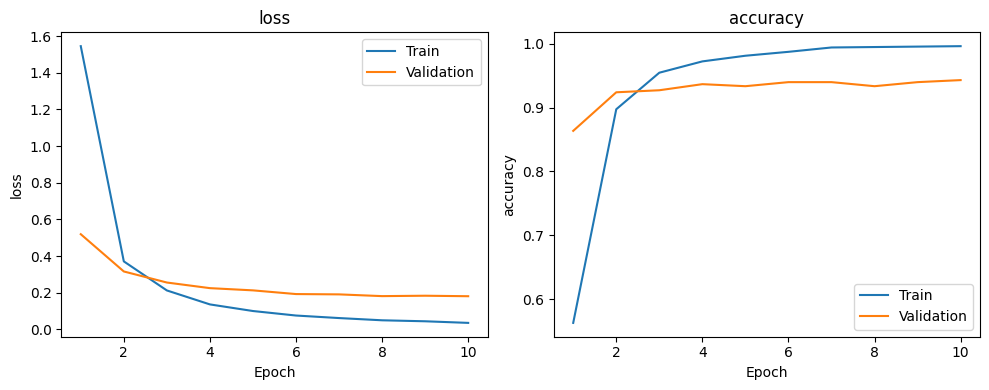

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
epochs = range(1, len(history.history["loss"]) + 1)

for ax, metric in zip(axes, ["loss", "accuracy"]):
    ax.plot(
        epochs,
        history.history[metric],
        label="Train"
    )
    ax.plot(
        epochs,
        history.history["val_" + metric],
        label="Validation"
    )
    ax.set(
        xlabel="Epoch",
        ylabel=metric,
        title=metric
    )
    ax.legend()

plt.tight_layout()
plt.show()

Test loss : 0.1661 | Test accuracy : 94.29%
                   precision    recall  f1-score   support

     agricultural       1.00      1.00      1.00        15
         airplane       0.94      1.00      0.97        15
  baseballdiamond       1.00      1.00      1.00        15
            beach       1.00      1.00      1.00        15
        buildings       0.78      0.93      0.85        15
        chaparral       1.00      1.00      1.00        15
 denseresidential       0.88      1.00      0.94        15
           forest       1.00      0.93      0.97        15
          freeway       0.93      0.87      0.90        15
       golfcourse       1.00      0.87      0.93        15
           harbor       1.00      1.00      1.00        15
     intersection       0.86      0.80      0.83        15
mediumresidential       0.87      0.87      0.87        15
   mobilehomepark       1.00      1.00      1.00        15
         overpass       0.94      1.00      0.97        15
       park

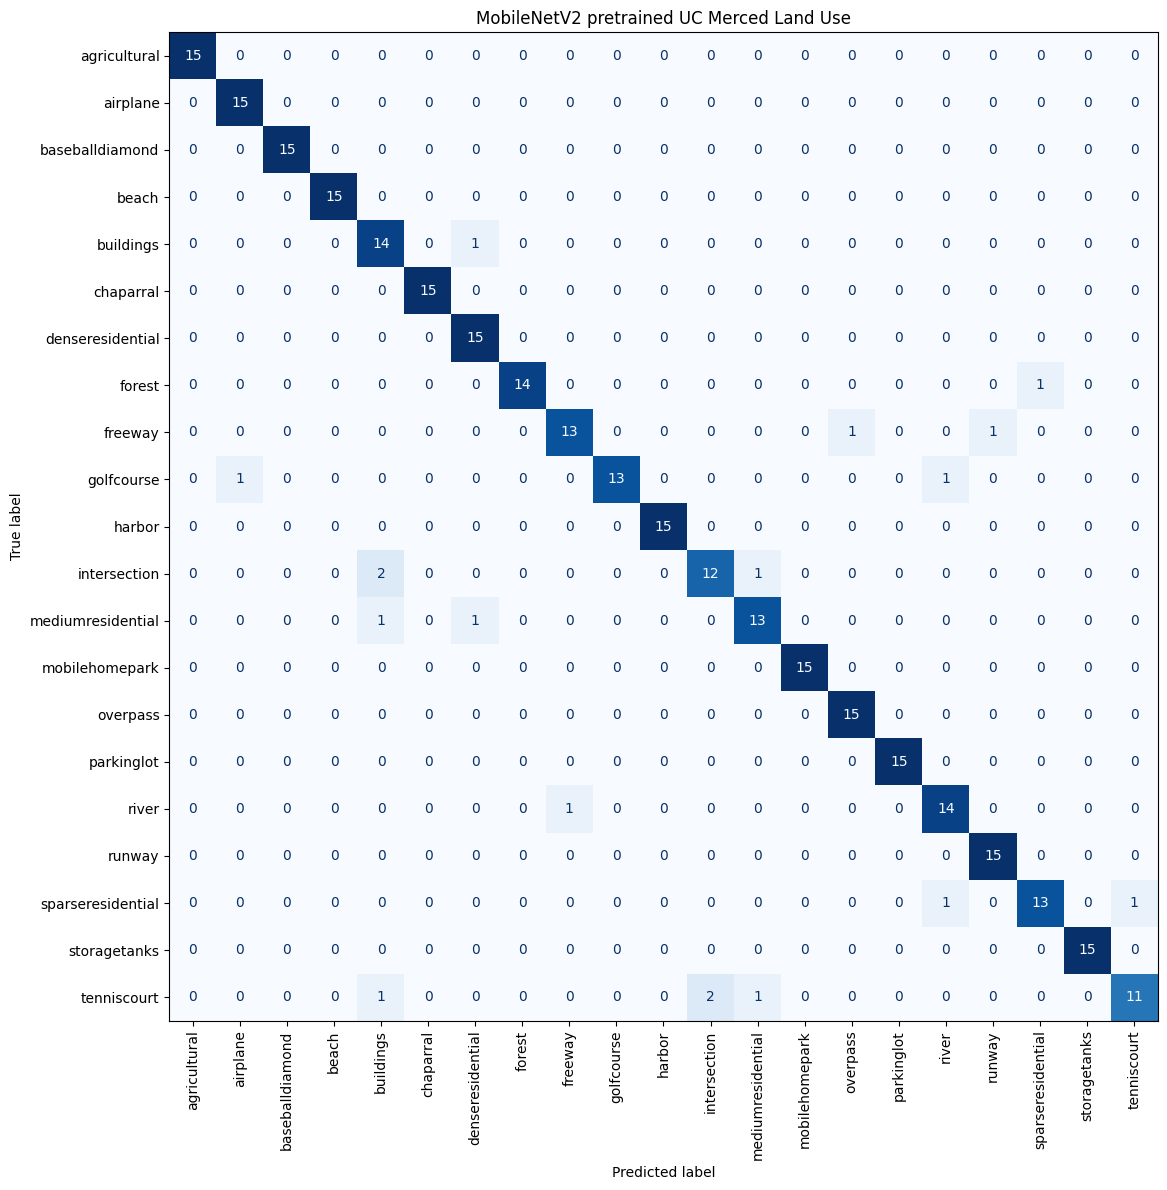

In [39]:
test_loss, test_acc = model.evaluate(
    x_test,
    y_test,
    verbose=0
)

probabilitas = model.predict(
    x_test,
    batch_size=BATCH_SIZE,
    verbose=0
)

y_pred = probabilitas.argmax(axis=1)

print(
    f"Test loss : {test_loss:.4f} | "
    f"Test accuracy : {test_acc:.2%}"
)

assert np.isclose(
    test_acc,
    np.mean(y_pred == y_test),
    atol=1e-6
)

print(
    classification_report(
        y_test,
        y_pred,
        target_names=nama_kelas,
        zero_division=0
    )
)

fig, ax = plt.subplots(figsize=(14, 12))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=nama_kelas,
    cmap="Blues",
    xticks_rotation=90,
    colorbar=False,
    ax=ax
)

ax.set_title("MobileNetV2 pretrained UC Merced Land Use")
plt.tight_layout()
plt.show()

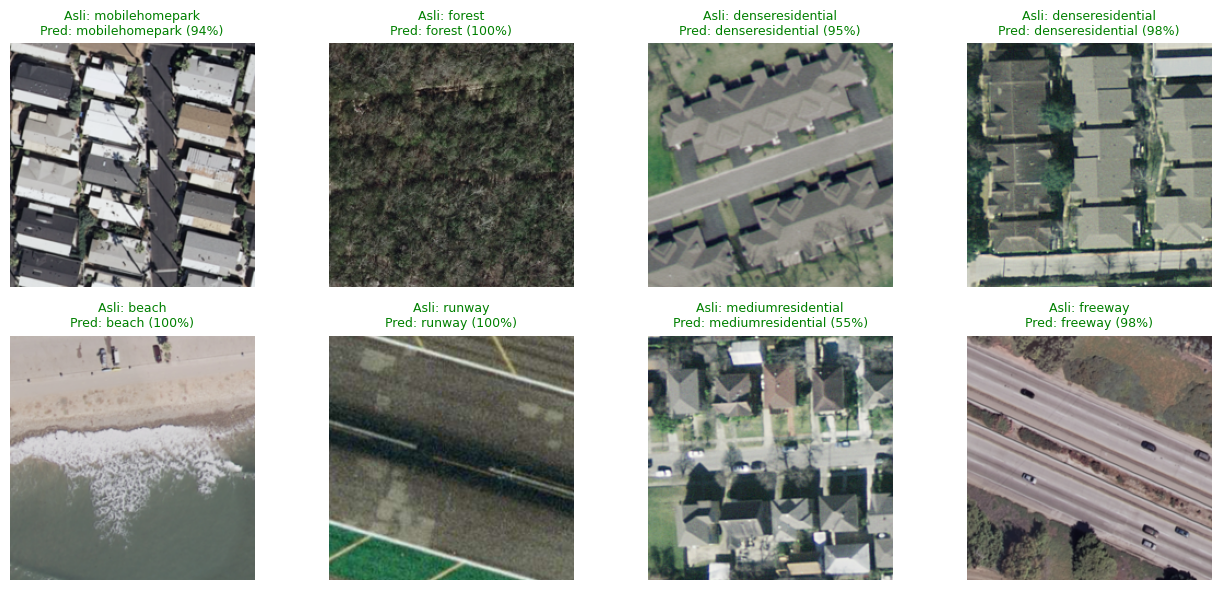

In [40]:
fig, axes = plt.subplots(2, 4, figsize=(13, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_test[i])
    ax.set_title(
        f"Asli: {nama_kelas[y_test[i]]}\n"
        f"Pred: {nama_kelas[y_pred[i]]} "
        f"({probabilitas[i].max():.0%})",
        fontsize=9,
        color="green" if y_test[i] == y_pred[i] else "red"
    )
    ax.axis("off")
plt.tight_layout()
plt.show()

b. Alexnet

In [41]:
inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))

# Convolutional layer 1
x = tf.keras.layers.Conv2D(
    96, kernel_size=11, strides=4,
    activation="relu", padding="valid"
)(inputs)
x = tf.keras.layers.MaxPooling2D(
    pool_size=3, strides=2
)(x)

# Convolutional layer 2
x = tf.keras.layers.Conv2D(
    256, kernel_size=5,
    activation="relu", padding="same"
)(x)
x = tf.keras.layers.MaxPooling2D(
    pool_size=3, strides=2
)(x)

# Convolutional layers 3, 4, and 5
x = tf.keras.layers.Conv2D(
    384, kernel_size=3,
    activation="relu", padding="same"
)(x)

x = tf.keras.layers.Conv2D(
    384, kernel_size=3,
    activation="relu", padding="same"
)(x)

x = tf.keras.layers.Conv2D(
    256, kernel_size=3,
    activation="relu", padding="same"
)(x)
x = tf.keras.layers.MaxPooling2D(
    pool_size=3, strides=2
)(x)

# Flatten and fully connected layers
x = tf.keras.layers.Flatten()(x)

x = tf.keras.layers.Dense(
    4096, activation="relu"
)(x)
x = tf.keras.layers.Dropout(0.5)(x)

x = tf.keras.layers.Dense(
    4096, activation="relu"
)(x)
x = tf.keras.layers.Dropout(0.5)(x)

# Output layer
outputs = tf.keras.layers.Dense(
    len(nama_kelas),
    activation="softmax"
)(x)

# Build model
model = tf.keras.Model(
    inputs,
    outputs,
    name="alexnet_ucmerced"
)

# Compile model
model.compile(
    optimizer=tf.keras.optimizers.Adam(0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "alexnet_ucmerced"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 54, 54, 96)     │        34,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 26, 26, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 26, 26, 256)    │       614,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 384)    │       885,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 12, 12, 384)    │     1,327,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 12, 12, 256)    │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 5, 5, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 4096)           │    26,218,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 21)             │        86,037 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 46,833,045 (178.65 MB)

 Trainable params: 46,833,045 (178.65 MB)

 Non-trainable params: 0 (0.00 B)

In [42]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop],
    verbose=2
)

print("Epoch dijalankan :", len(history.history["loss"]))

Epoch 1/10
92/92 - 23s - 250ms/step - accuracy: 0.0605 - loss: 8.4903 - val_accuracy: 0.0476 - val_loss: 3.0438
Epoch 2/10
92/92 - 3s - 31ms/step - accuracy: 0.0503 - loss: 3.0414 - val_accuracy: 0.0476 - val_loss: 2.9448
Epoch 3/10
92/92 - 3s - 31ms/step - accuracy: 0.0844 - loss: 2.8873 - val_accuracy: 0.1460 - val_loss: 2.7339
Epoch 4/10
92/92 - 3s - 31ms/step - accuracy: 0.1218 - loss: 2.7110 - val_accuracy: 0.1810 - val_loss: 2.6070
Epoch 5/10
92/92 - 3s - 31ms/step - accuracy: 0.1551 - loss: 2.6011 - val_accuracy: 0.1460 - val_loss: 2.5763
Epoch 6/10
92/92 - 3s - 31ms/step - accuracy: 0.1639 - loss: 2.6113 - val_accuracy: 0.1937 - val_loss: 2.4443
Epoch 7/10
92/92 - 3s - 31ms/step - accuracy: 0.1912 - loss: 2.4989 - val_accuracy: 0.2127 - val_loss: 2.2860
Epoch 8/10
92/92 - 3s - 29ms/step - accuracy: 0.2020 - loss: 2.4728 - val_accuracy: 0.1810 - val_loss: 2.4387
Epoch 9/10
92/92 - 3s - 29ms/step - accuracy: 0.2150 - loss: 2.3745 - val_accuracy: 0.2159 - val_loss: 2.3375
Epoch 10

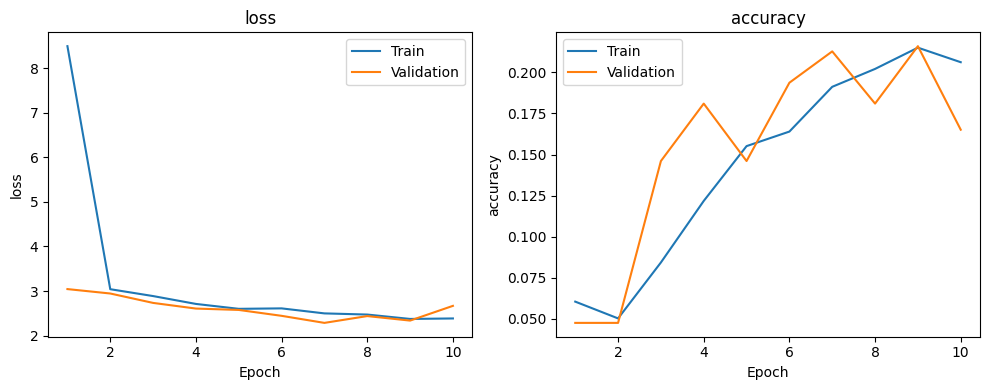

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
epochs = range(1, len(history.history["loss"]) + 1)

for ax, metric in zip(axes, ["loss", "accuracy"]):
    ax.plot(
        epochs,
        history.history[metric],
        label="Train"
    )
    ax.plot(
        epochs,
        history.history["val_" + metric],
        label="Validation"
    )
    ax.set(
        xlabel="Epoch",
        ylabel=metric,
        title=metric
    )
    ax.legend()

plt.tight_layout()
plt.show()

Test loss : 2.3010 | Test accuracy : 21.27%
                   precision    recall  f1-score   support

     agricultural       0.24      0.93      0.38        15
         airplane       0.64      0.47      0.54        15
  baseballdiamond       0.53      0.60      0.56        15
            beach       0.00      0.00      0.00        15
        buildings       1.00      0.13      0.24        15
        chaparral       0.00      0.00      0.00        15
 denseresidential       0.00      0.00      0.00        15
           forest       0.33      0.13      0.19        15
          freeway       0.16      0.33      0.21        15
       golfcourse       0.12      0.07      0.09        15
           harbor       0.31      0.27      0.29        15
     intersection       0.00      0.00      0.00        15
mediumresidential       0.08      0.07      0.07        15
   mobilehomepark       0.17      0.87      0.29        15
         overpass       0.09      0.20      0.12        15
       park

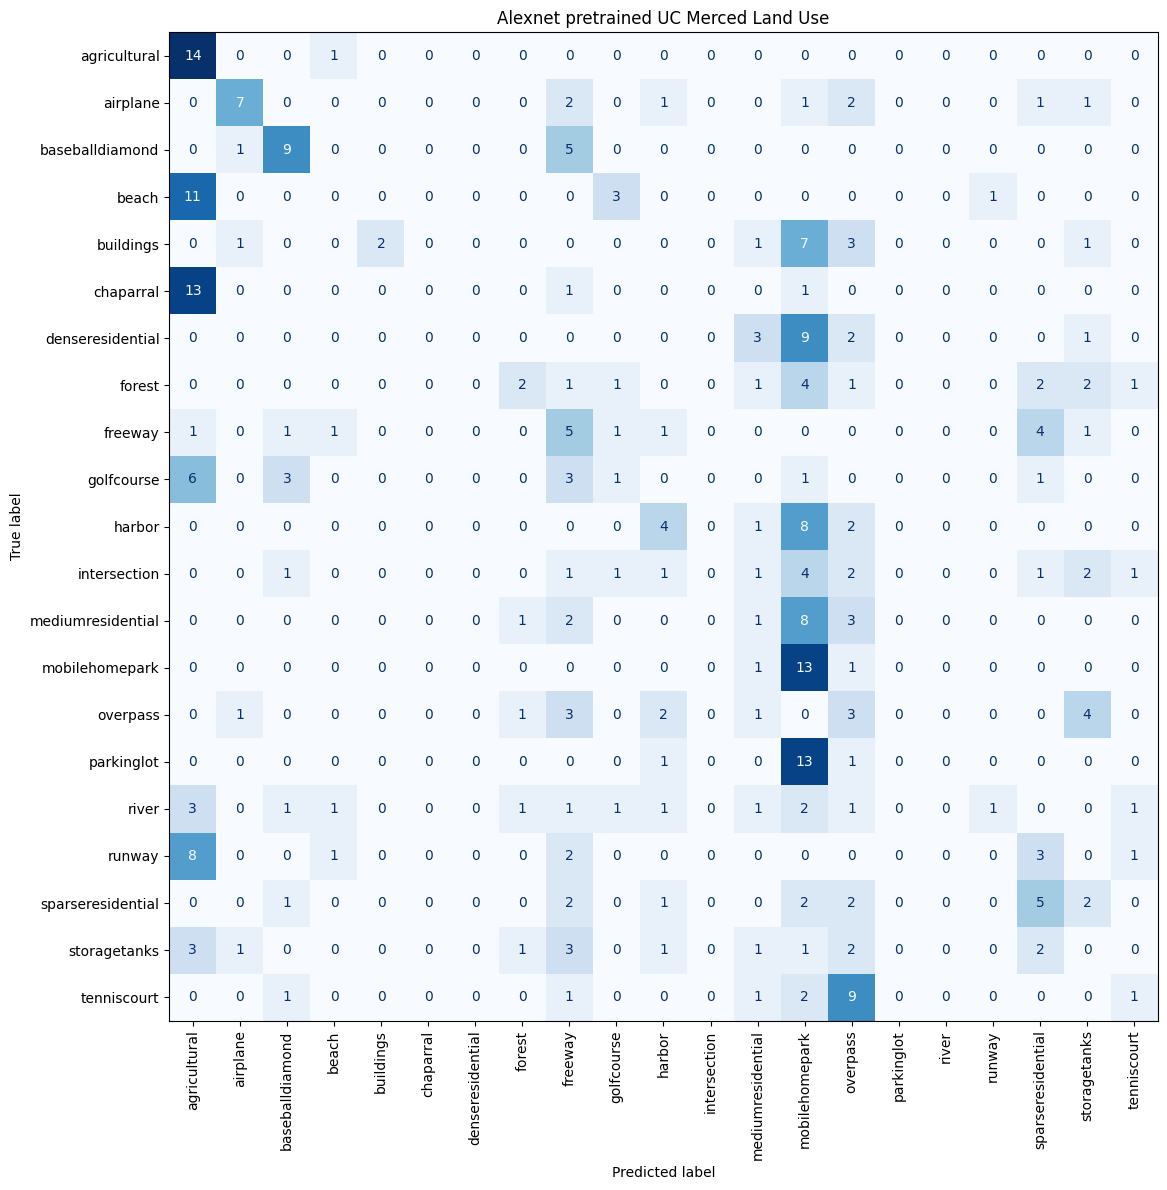

In [44]:
test_loss, test_acc = model.evaluate(
    x_test,
    y_test,
    verbose=0
)

probabilitas = model.predict(
    x_test,
    batch_size=BATCH_SIZE,
    verbose=0
)

y_pred = probabilitas.argmax(axis=1)

print(
    f"Test loss : {test_loss:.4f} | "
    f"Test accuracy : {test_acc:.2%}"
)

assert np.isclose(
    test_acc,
    np.mean(y_pred == y_test),
    atol=1e-6
)

print(
    classification_report(
        y_test,
        y_pred,
        target_names=nama_kelas,
        zero_division=0
    )
)

fig, ax = plt.subplots(figsize=(14, 12))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=nama_kelas,
    cmap="Blues",
    xticks_rotation=90,
    colorbar=False,
    ax=ax
)

ax.set_title("Alexnet pretrained UC Merced Land Use")
plt.tight_layout()
plt.show()

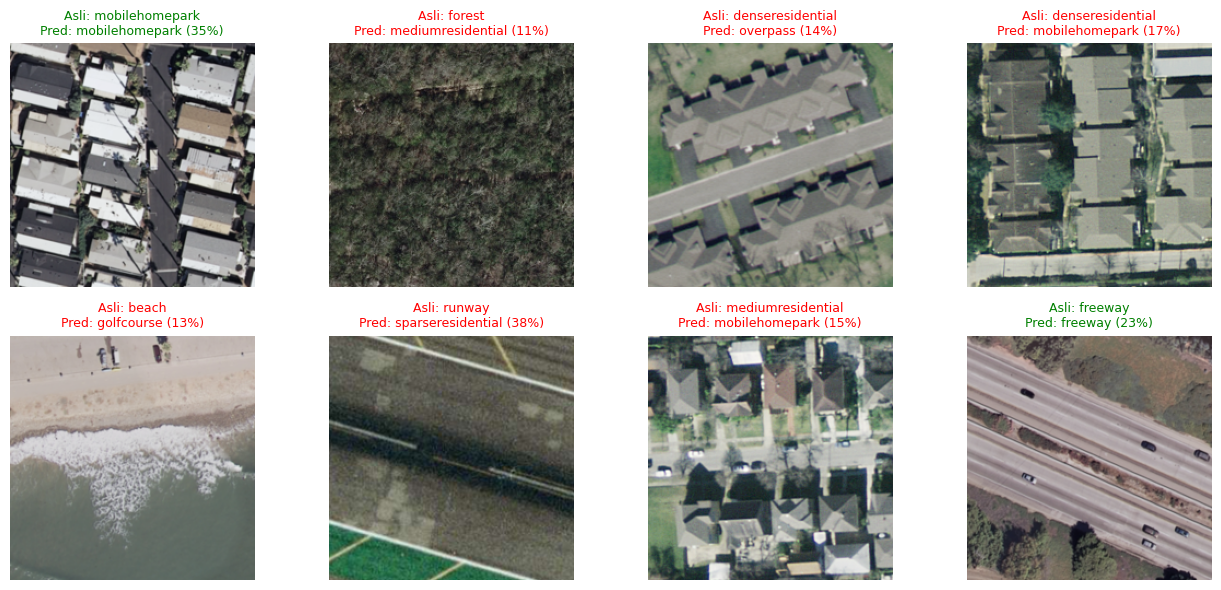

In [45]:
fig, axes = plt.subplots(2, 4, figsize=(13, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_test[i])
    ax.set_title(
        f"Asli: {nama_kelas[y_test[i]]}\n"
        f"Pred: {nama_kelas[y_pred[i]]} "
        f"({probabilitas[i].max():.0%})",
        fontsize=9,
        color="green" if y_test[i] == y_pred[i] else "red"
    )
    ax.axis("off")
plt.tight_layout()
plt.show()

Kesimpulan : Berdasarkan hasil pengujian terhadap 315 data citra, MobileNet memperoleh akurasi tertinggi sebesar 94,29% dengan test loss 0,1661. ResNetpada metode praktikum ke 2 memperoleh akurasi 93,65% dengan test loss terendah sebesar 0,1602, sedangkan VGG menghasilkan akurasi 92,70%. Ketiga model tersebut menunjukkan kemampuan klasifikasi yang baik. Sementara itu, AlexNet hanya memperoleh akurasi 21,27% dengan test loss 2,3010, yang menunjukkan bahwa model belum mampu mengklasifikasikan citra secara optimal. Dengan demikian, MobileNet menjadi model terbaik berdasarkan akurasi, sedangkan ResNet memiliki nilai test loss terendah.
